## Setup Model

#### API Key

In [61]:
import os
from dotenv import load_dotenv

load_dotenv()

api_key =  os.getenv("OPEN_ROUTER_API_KEY")

#### Load Model

In [62]:
from langchain_openai import ChatOpenAI

base_url = "https://openrouter.ai/api/v1"
model = "openrouter/free"

llm = ChatOpenAI(
    api_key = api_key,
    base_url = base_url,
    model = model,
    temperature = 0.8
)

#### Test Model

In [63]:
from IPython.display import display , Markdown

response = llm.invoke("tell me 10 countries").content

display(Markdown(response))

Here are 10 countries from different regions around the world, chosen for geographic and cultural diversity:

1. **United States** (North America)  
2. **Brazil** (South America)  
3. **Canada** (North America)  
4. **France** (Europe)  
5. **Germany** (Europe)  
6. **India** (Asia)  
7. **Japan** (Asia)  
8. **Nigeria** (Africa)  
9. **Australia** (Oceania)  
10. **Indonesia** (Asia)  

*Note: This list includes sovereign UN member states spanning all inhabited continents. If you'd like countries with specific traits (e.g., smallest, most populous, island nations), let me know!* 😊

## Load Knowledge file

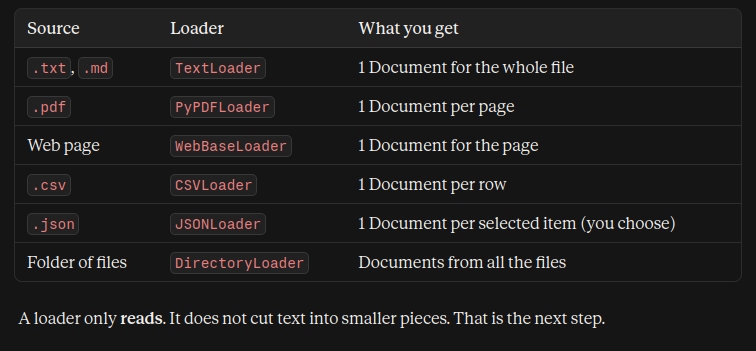

In [64]:
from langchain_community.document_loaders import JSONLoader


def metadata_func(record, metadata):

    metadata["id"] = record["id"]
    metadata["type"] = record["type"]
    metadata["title"] = record["title"]
    metadata["parent_id"] = record.get("parent_id")
    return metadata


loader = JSONLoader(
    file_path="knowledge.json",
    jq_schema=".[]",            
    content_key="text",       
    metadata_func=metadata_func,
)


documents = loader.load()

In [65]:
len(documents)

38

## Chunking Concept

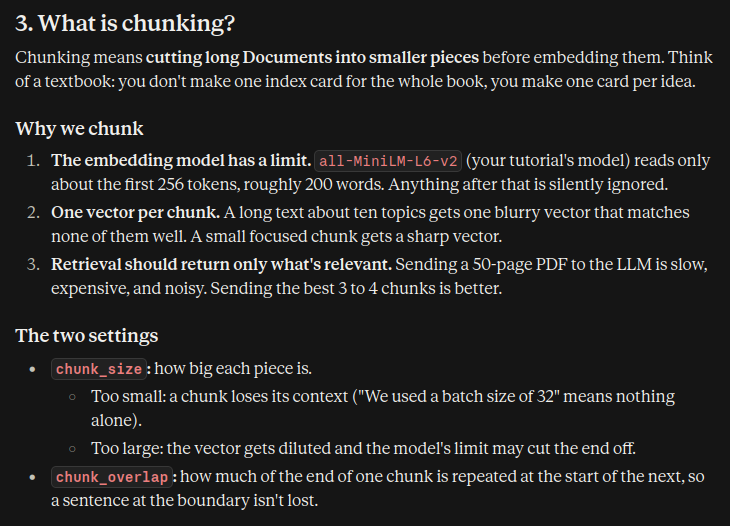

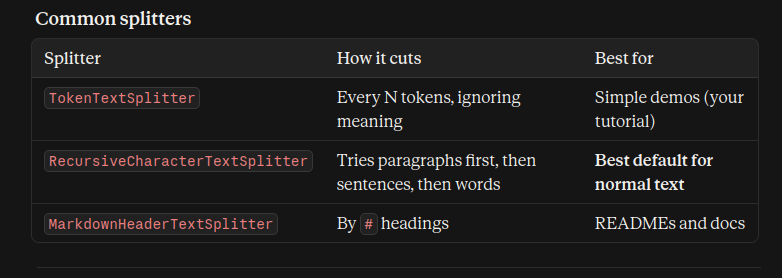

## When we don't need splitter ?

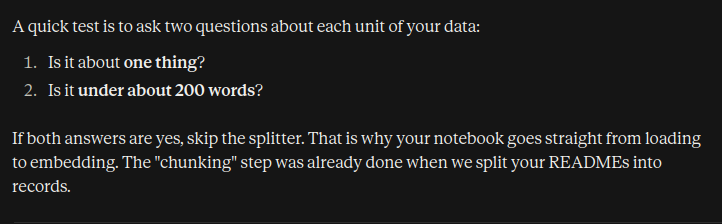

#### Because i use llm to build json file from all my md & pdfs files , the json file is about 38 idea & under 200 word for each idea/json part .

#### There was another way , load each md file isolated : clean them , chunk them . then combine & load . 

In [66]:
sizes = [len(d.page_content.split()) for d in documents]
print("min", min(sizes), "| max", max(sizes), "| average", round(sum(sizes) / len(sizes)))

min 23 | max 110 | average 64


## Embedding

In [67]:
from langchain_community.embeddings import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(

    model_name = "sentence-transformers/all-MiniLM-L6-v2",

    model_kwargs = {"device":"cpu"}

)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2953.23it/s]


## Vector Store

In [68]:
from langchain_classic.vectorstores import FAISS

vectorDB = FAISS.from_documents(documents, embeddings)

## Test Retrieval

In [69]:
query = "Which projects did he use Docker in?"

for doc, score in vectorDB.similarity_search_with_score(query, k=4):

    print(round(float(score), 3), "|", doc.metadata["id"], "|", doc.metadata['title'] , "|", doc.page_content)

0.908 | skill-docker-cloud | Docker and AWS cloud | Abdelrahman Gaber uses Docker and Docker Compose to package multi-service apps, and has deployed the OCR system on AWS using S3 for image storage, RDS PostgreSQL for metadata, ECR for images, ECS for running containers, and CloudWatch for logs, Container Insights and alarms. He studied Cloud Computing at university.
1.222 | skill-linux-tools | Linux and developer tools | Abdelrahman Gaber works daily on Linux (Ubuntu and Void; LinkedIn describes him as a Linux aficionado) and uses Git, Docker and Postman, shell scripts for automation (such as run_local.sh in the OCR project), and virtual environments.
1.296 | skill-mlops-deployment | MLOps and model deployment | Abdelrahman Gaber builds production-style ML systems: modular pipelines (ingestion, transformation, training, evaluation, prediction), custom logging and exception handling, experiment tracking with MLflow, Streamlit apps deployed on Streamlit Cloud, and containerized services

## Setup Prompts

In [70]:
from langchain_core.prompts import SystemMessagePromptTemplate , HumanMessagePromptTemplate , ChatPromptTemplate

    
system_rules = """You are an assistant that answers questions about Abdelrahman Gaber using ONLY the provided context.

Rules:
- If the answer is not in the context, say you don't know.
- If a project's ownership is "unknown" or "team", do not claim he built it alone or state his role.
- Keep the answer under 200 words.
- Answer in the same language the user wrote the question in."""


system_msg = SystemMessagePromptTemplate.from_template(system_rules)

human_msg = HumanMessagePromptTemplate.from_template(
    "Context:\n{context}\n\nQuestion:\n{question}"
)


chat_template = ChatPromptTemplate.from_messages([system_msg, human_msg])

In [71]:
chat_template

ChatPromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template='You are an assistant that answers questions about Abdelrahman Gaber using ONLY the provided context.\n\nRules:\n- If the answer is not in the context, say you don\'t know.\n- If a project\'s ownership is "unknown" or "team", do not claim he built it alone or state his role.\n- Keep the answer under 200 words.\n- Answer in the same language the user wrote the question in.'), additional_kwargs={}), HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, template='Context:\n{context}\n\nQuestion:\n{question}'), additional_kwargs={})])

## Search

In [72]:
doc_by_id = {d.metadata["id"]: d for d in documents}

def retrieve(query, k=4):

    results = vectorDB.similarity_search(query, k=k)

    final = []

    for d in results:
        final.append(d)                                      
        parent = doc_by_id.get(d.metadata.get("parent_id"))  
        
        if parent:
            final.append(parent)

    # remove duplicates, keep the order
    unique = {d.metadata["id"]: d for d in final}
    
    return list(unique.values())

In [73]:
def ask(question, k=4):
    
    docs = retrieve(question, k=k) 
    
    context = "\n\n".join(d.page_content for d in docs)
    
    messages = chat_template.format_messages(context=context, question=question) 
    
    
    return llm.invoke(messages).content                    

### Test Search

In [74]:
from IPython.display import display, Markdown

response = ask("when abdelrahman joined helwan univ. ?")

display(Markdown(response))

Abdelrahman Gaber joined Helwan University in **October 2023** to start his B.Sc. in Computer Science (AI specialization).

## Evaluate with Recall@

For each question we write which record ids **should** be found. **Recall@K** = the share of questions where at least
one expected record appears in the top K results. Run it again after every change (header on/off, different model, filters) and compare.

In [76]:
eval_set_2 = [
    
    ("Is he still a student?",                                  {"edu-helwan", "about-summary"}),
    ("Where does he live?",                                     {"about-summary"}),
    ("Is he good at algorithms?",                               {"skill-problem-solving"}),
    ("What did he do in 2025?",                                 {"about-timeline", "exp-depi", "exp-itech", "proj-production-pipeline"}),
    ("Does he know C++?",                                       {"skill-languages"}),
  
    ("How is the OCR system monitored?",                        {"proj-ocr-aws"}),
    ("What accuracy did the production pipeline reach?",        {"proj-production-pipeline"}),
    ("What embedding size and hidden dimension did he use?",    {"proj-toxic-models"}),
    ("What are the engagement levels in SEMSOL?",               {"proj-semsol-engagement"}),
    ("How does the portal handle uploaded images?",             {"proj-content-portal"}),
    ("What text preprocessing did he apply to comments?",       {"proj-toxic-data"}),
    ("Which datasets were used for gaze models?",               {"proj-semsol", "ref-mobilegaze"}),
   
    ("Which projects use PyTorch?",                             {"proj-toxic-comments", "proj-ocr", "proj-semsol", "proj-content-portal", "skill-deep-learning"}),
    ("Has he built anything with FastAPI?",                     {"proj-ocr", "skill-backend-apis"}),
    ("Which tools does he use to deploy ML apps?",              {"skill-mlops-deployment", "proj-bmw-classification"}),
    ("Which team projects has he done?",                        {"proj-ocr", "proj-semsol"}),
   
    ("What is his strongest area?",                             {"about-summary", "skill-deep-learning", "skill-computer-vision"}),
    ("Did he work on dashboards at a company?",                 {"exp-itech", "skill-erpnext", "skill-data-viz"}),
    ("What has he built with computer vision?",                 {"skill-computer-vision", "proj-ocr", "proj-semsol", "proj-content-portal"}),
]

def recall_at_k(k):
    hits = 0
    for q, expected in eval_set:
        found = {d.metadata["id"] for d in vectorDB.similarity_search(q, k=k)}
        if found & expected:
            hits += 1
    return hits / len(eval_set)

for k in (1, 3, 5, 7):
    print(f"Recall@{k}: {recall_at_k(k):.2f}")

Recall@1: 0.83
Recall@3: 1.00
Recall@5: 1.00
Recall@7: 1.00
